#  Experiment 3: Exploratory Data Analysis (EDA)

---
### **Aim / Objective:**
To conduct in-depth Exploratory Data Analysis, uncover distributions, correlations, detect outliers, and generate actionable summary insights.

---
### **Theory & Overview:**
Exploratory Data Analysis (EDA) is the foundational step in data modeling:
- **Univariate Analysis**: Histograms, Kernel Density Estimation (KDE), Box Plots.
- **Bivariate & Multivariate Analysis**: Scatter plots, pair plots, and correlation heatmaps.
- **Outlier Detection**: Interquartile Range (IQR) rule: Outliers lie outside $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$.



### **1. Load Dataset and Initial Inspection**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Load standard Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

print("--- Dataset Shape & Info ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(df.info())
print("\n--- Descriptive Statistics ---")
print(df.describe())



--- Dataset Shape & Info ---
Rows: 150, Columns: 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

--- Descriptive Statistics ---
       sepal length (cm)  sepal width (cm)  ...  petal width (cm)      target
count         150.000000        150.000000  ...        150.000000  150.000000
mean            5.843333          3.057333  ...          1.199333    1.000000
std             0.828066          0.435866  ...          0.762238    0.819232
min             4.300000          2.000000  ...   

### **2. Visualizing Distributions & KDE Plots**


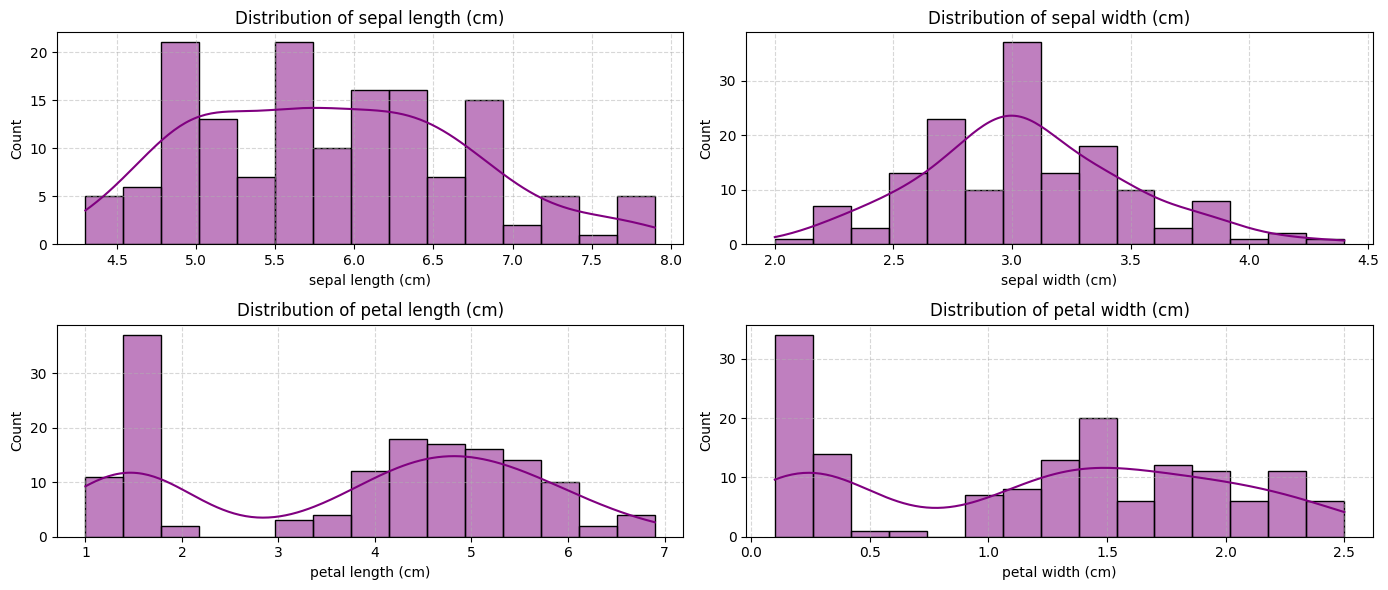

In [ ]:
plt.figure(figsize=(14, 6))

features = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True, color='purple', bins=15)
    plt.title(f"Distribution of {col}")
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()



### **3. Correlation Analysis & Heatmap**


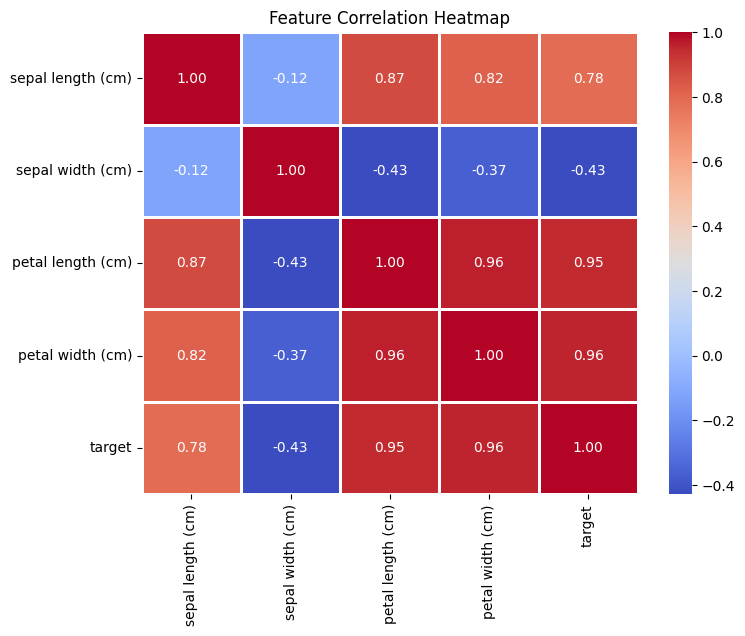

High correlation observed between petal length and petal width: 0.962865431402796


In [ ]:
plt.figure(figsize=(8, 6))
numeric_df = df.drop(columns=['species'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=1)
plt.title("Feature Correlation Heatmap")
plt.show()

print("High correlation observed between petal length and petal width:",
      corr_matrix.loc['petal length (cm)', 'petal width (cm)'])



### **4. Outlier Detection using Box Plots & IQR Method**


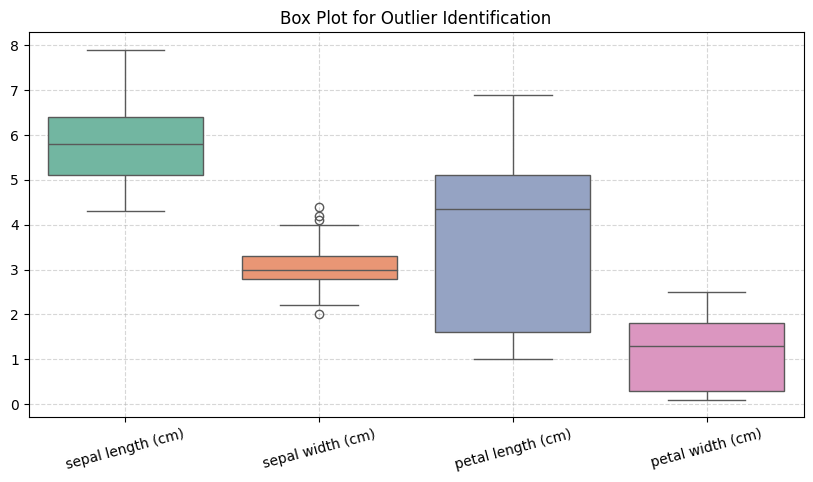

Sepal Width IQR Bounds: [2.05, 4.05]
Number of Outliers Identified: 4


In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[features], palette='Set2')
plt.title("Box Plot for Outlier Identification")
plt.xticks(rotation=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Calculate IQR for Sepal Width
q1 = df['sepal width (cm)'].quantile(0.25)
q3 = df['sepal width (cm)'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['sepal width (cm)'] < lower_bound) | (df['sepal width (cm)'] > upper_bound)]
print(f"Sepal Width IQR Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of Outliers Identified: {len(outliers)}")



### **5. Pairplot for Multi-Class Feature Discrimination**


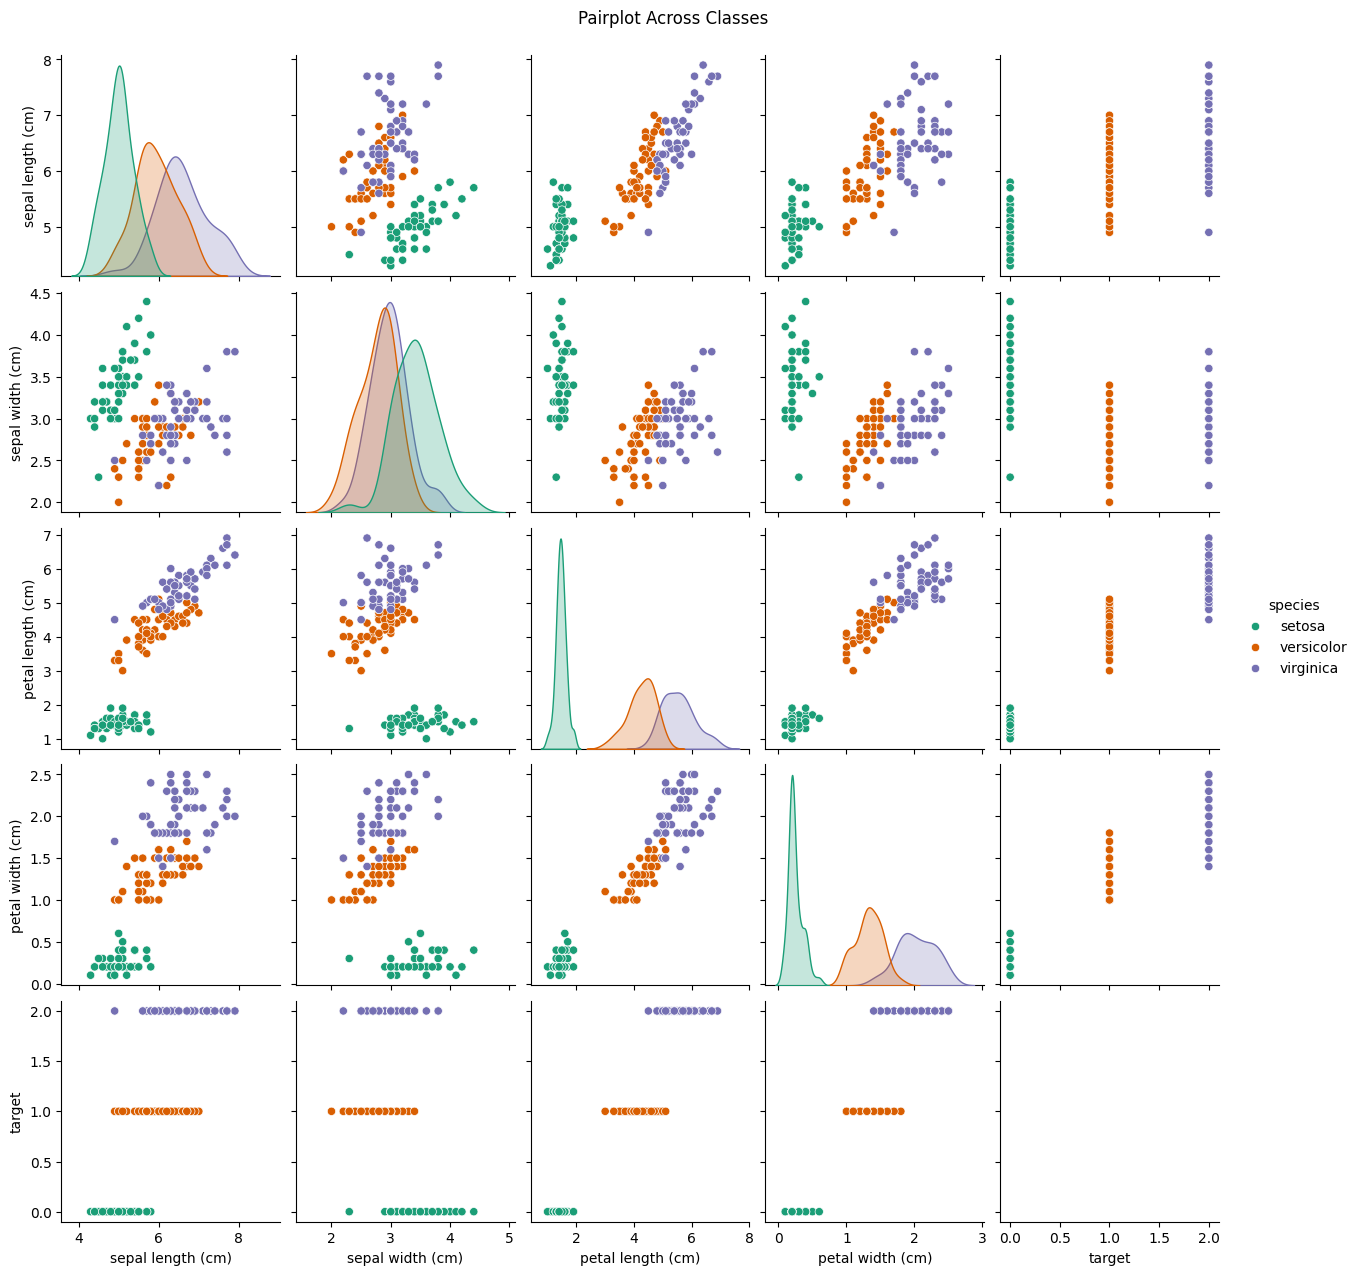

In [ ]:
sns.pairplot(df, hue='species', palette='Dark2', diag_kind='kde')
plt.suptitle("Pairplot Across Classes", y=1.02)
plt.show()



---
### **Conclusion & Learning Outcomes:**
Completed comprehensive EDA on multi-dimensional data, extracting statistical metrics, identifying outliers using IQR boundaries, and discovering strong linear correlations through heatmaps and pair plots.
